# Graphe de proximité sémantique de mots français

Pipeline principal du projet (SEME Marseille) :

1. pour chaque mot français, on récupère ses **synsets** WordNet (via OMW, `lang='fra'`) et leurs définitions ;
2. WordNet fournit les définitions en anglais : on les **traduit en français** (`googletrans`) ;
3. chaque définition est encodée avec **CamemBERT** ; la similarité entre deux définitions est le **cosinus** des représentations moyennes des tokens ;
4. on construit un **graphe** (`networkx`) dont les nœuds sont les définitions et dont les arêtes relient les définitions de similarité > 0,8.

**Dépendances** : voir `requirements.txt` à la racine du dépôt. Le notebook lit `../data/data_toyes.txt` et écrit la figure dans `../figures/`. Il nécessite un accès Internet (téléchargement de CamemBERT, de WordNet et appel au service de traduction).

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import CamembertForMaskedLM, AutoTokenizer
from googletrans import Translator   # pip install googletrans==4.0.0-rc1
import nltk
from nltk.corpus import wordnet as wn
import networkx as nx
import matplotlib.pyplot as plt

nltk.download('wordnet')
nltk.download('omw-1.4')

## 1. Modèle CamemBERT

In [ ]:
camembert = CamembertForMaskedLM.from_pretrained('camembert-base')

## 2. Choix des mots

Échantillon aléatoire de mots courants (fixé par `random_state` pour la reproductibilité), puis liste de mots utilisée pour la suite.

In [ ]:
import pandas as pd
df = pd.read_csv('../data/data_toyes.txt', header= None, sep = '\t')
df = df[[1]]
lst_mots = df.sample(50, random_state=0).values
lst_mots

## 3. Fonctions de traduction

In [8]:
def get_french_translation(word):
    translator = Translator()
    translation = translator.translate(word, src='en', dest='fr')
    return translation.text

def get_english_tranlation(word):
    translator = Translator()
    translation = translator.translate(word, src='fr', dest='en')
    return translation.text

# Exemple d'utilisation
mot_a_definir = "travel in an automobile"
resultat = get_french_translation(mot_a_definir)
print(resultat)
res2 = get_english_tranlation(resultat)
print(res2)

voyager en automobile
travel by car


## 4. Fonctions WordNet et représentations vectorielles

In [ ]:
def get_synset(mot):
    lst_synset = wn.synsets(str(mot), lang = 'fra')
    return(lst_synset)

def get_def(synset):
    definition = synset.definition()
    return(definition)

def take_first_embedding(embeddings, attention_mask=None):
    return embeddings[:, 0]

def average_embeddings(embeddings, attention_mask):
    return (attention_mask[..., None] * embeddings).mean(1)

## 5. Fonctions du pipeline

`def_lst_mots` renvoie les définitions (traduites) de tous les synsets d'une liste de mots ; `similarite_camembert` calcule la similarité cosinus entre toutes les paires de définitions.

In [ ]:
def def_lst_mots(lst_mots):
    lst_synset_m = []
    for m in lst_mots:
        print('mot', m)
        lst_synset_m.append(get_synset(m[0]))
    # print(len(lst_synset_m))
    new_lst_synset_m = []
    for j in lst_synset_m:
        for k in j:
            new_lst_synset_m.append(k)
    lst_def = []
    for i in new_lst_synset_m:
        lst_def.append(get_def(i))
    print('lst_def', lst_def)
    lst_def_trad_fr = []
    for k in lst_def:
        lst_def_trad_fr.append(get_french_translation(k))
    batch_sentences = lst_def_trad_fr
    print(batch_sentences)
    return(batch_sentences)

def similarite_camembert(batch_sentences):
    tokenizer = AutoTokenizer.from_pretrained('camembert-base')
    tokenizer_output = tokenizer(
        batch_sentences,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )
    with torch.no_grad():
        model_output = camembert(**tokenizer_output, output_hidden_states=True)
    token_embeddings = model_output.hidden_states[-1]
    first_tok_sentence_representations = take_first_embedding(token_embeddings, tokenizer_output.attention_mask)
    avg_sentence_representations = average_embeddings(token_embeddings, tokenizer_output.attention_mask)
    # Score
    lst_score = []
    for i in range(len(batch_sentences)):
        for j in range(len(batch_sentences)):
            for sent_id_1, sent_id_2 in [[i, j]]:
                first_tok_similarity_score = F.cosine_similarity(first_tok_sentence_representations[sent_id_1], first_tok_sentence_representations[sent_id_2], dim = -1)
                avg_similarity_score = F.cosine_similarity(avg_sentence_representations[sent_id_1], avg_sentence_representations[sent_id_2], dim = -1)
            s = list()
            S = 0
            for k in range(512):
                s.append(F.cosine_similarity(token_embeddings[i,k], token_embeddings[j,k], dim = -1))
            S = np.mean(s)

            print(f"{batch_sentences[sent_id_1]}    vs.    {batch_sentences[sent_id_2]}")
            # print(f"Score (first_tok) : {first_tok_similarity_score}")
            print(f"Score (average) : {avg_similarity_score}")
            lst_score.append(avg_similarity_score)
            # lst_score.append(avg_similarity_score)
            # print(f"Score (average embedding) : {S}\n")
    return(lst_score)

## 6. Exemple : « orange » et « voiture »

In [ ]:
lst_mots = np.array([['orange'], ['voiture'], ['couleur'], ['manger'],['système']])

In [ ]:
batch_sentences = def_lst_mots(lst_mots[0:2])
# batch_sentences

Pour ne pas dépendre du service de traduction, on reprend ici les définitions (déjà traduites) obtenues ci-dessus pour `lst_mots[0:2]` :

In [ ]:
batch_sentences = ["de la couleur entre le rouge et le jaune;Semblable à la couleur d'une orange mûre",
 "couleur orange ou pigment;n'importe laquelle d'une gamme de couleurs entre le rouge et le jaune",
 "une réserve faite de la pulpe et de l'écorce des agrumes",
 "Fruit jaune à orange rond de l'un des plusieurs agrumes",
 "une province du centre de l'Afrique du Sud colonisée par les Boers;Nommé État libre en 1997",
 "Une rivière en Afrique du Sud qui coule généralement vers l'ouest vers l'océan Atlantique",
 'TOUTES les agrumes portant des oranges',
 'Tout pigment produisant la couleur orange',
 'voyager dans une automobile',
 'Un transport pour les passagers ou le fret sur un câble ferroviaire',
 'un véhicule à moteur avec quatre roues;généralement propulsé par un moteur à combustion interne',
 'un véhicule à roues adapté aux rails du chemin de fer',
 'où les passagers montent et descendent',
 'un wagon où les passagers roulent']

In [ ]:
lst_score = similarite_camembert(batch_sentences)

In [ ]:
T = []
for i in range(len(lst_score)):
    T.append(lst_score[i].detach().numpy())
Tableau = np.array(T).reshape([14,14])

## 7. Graphe de similarité

Une arête relie deux définitions de similarité supérieure à 0,8 ; les nœuds sont numérotés dans l'ordre des définitions.

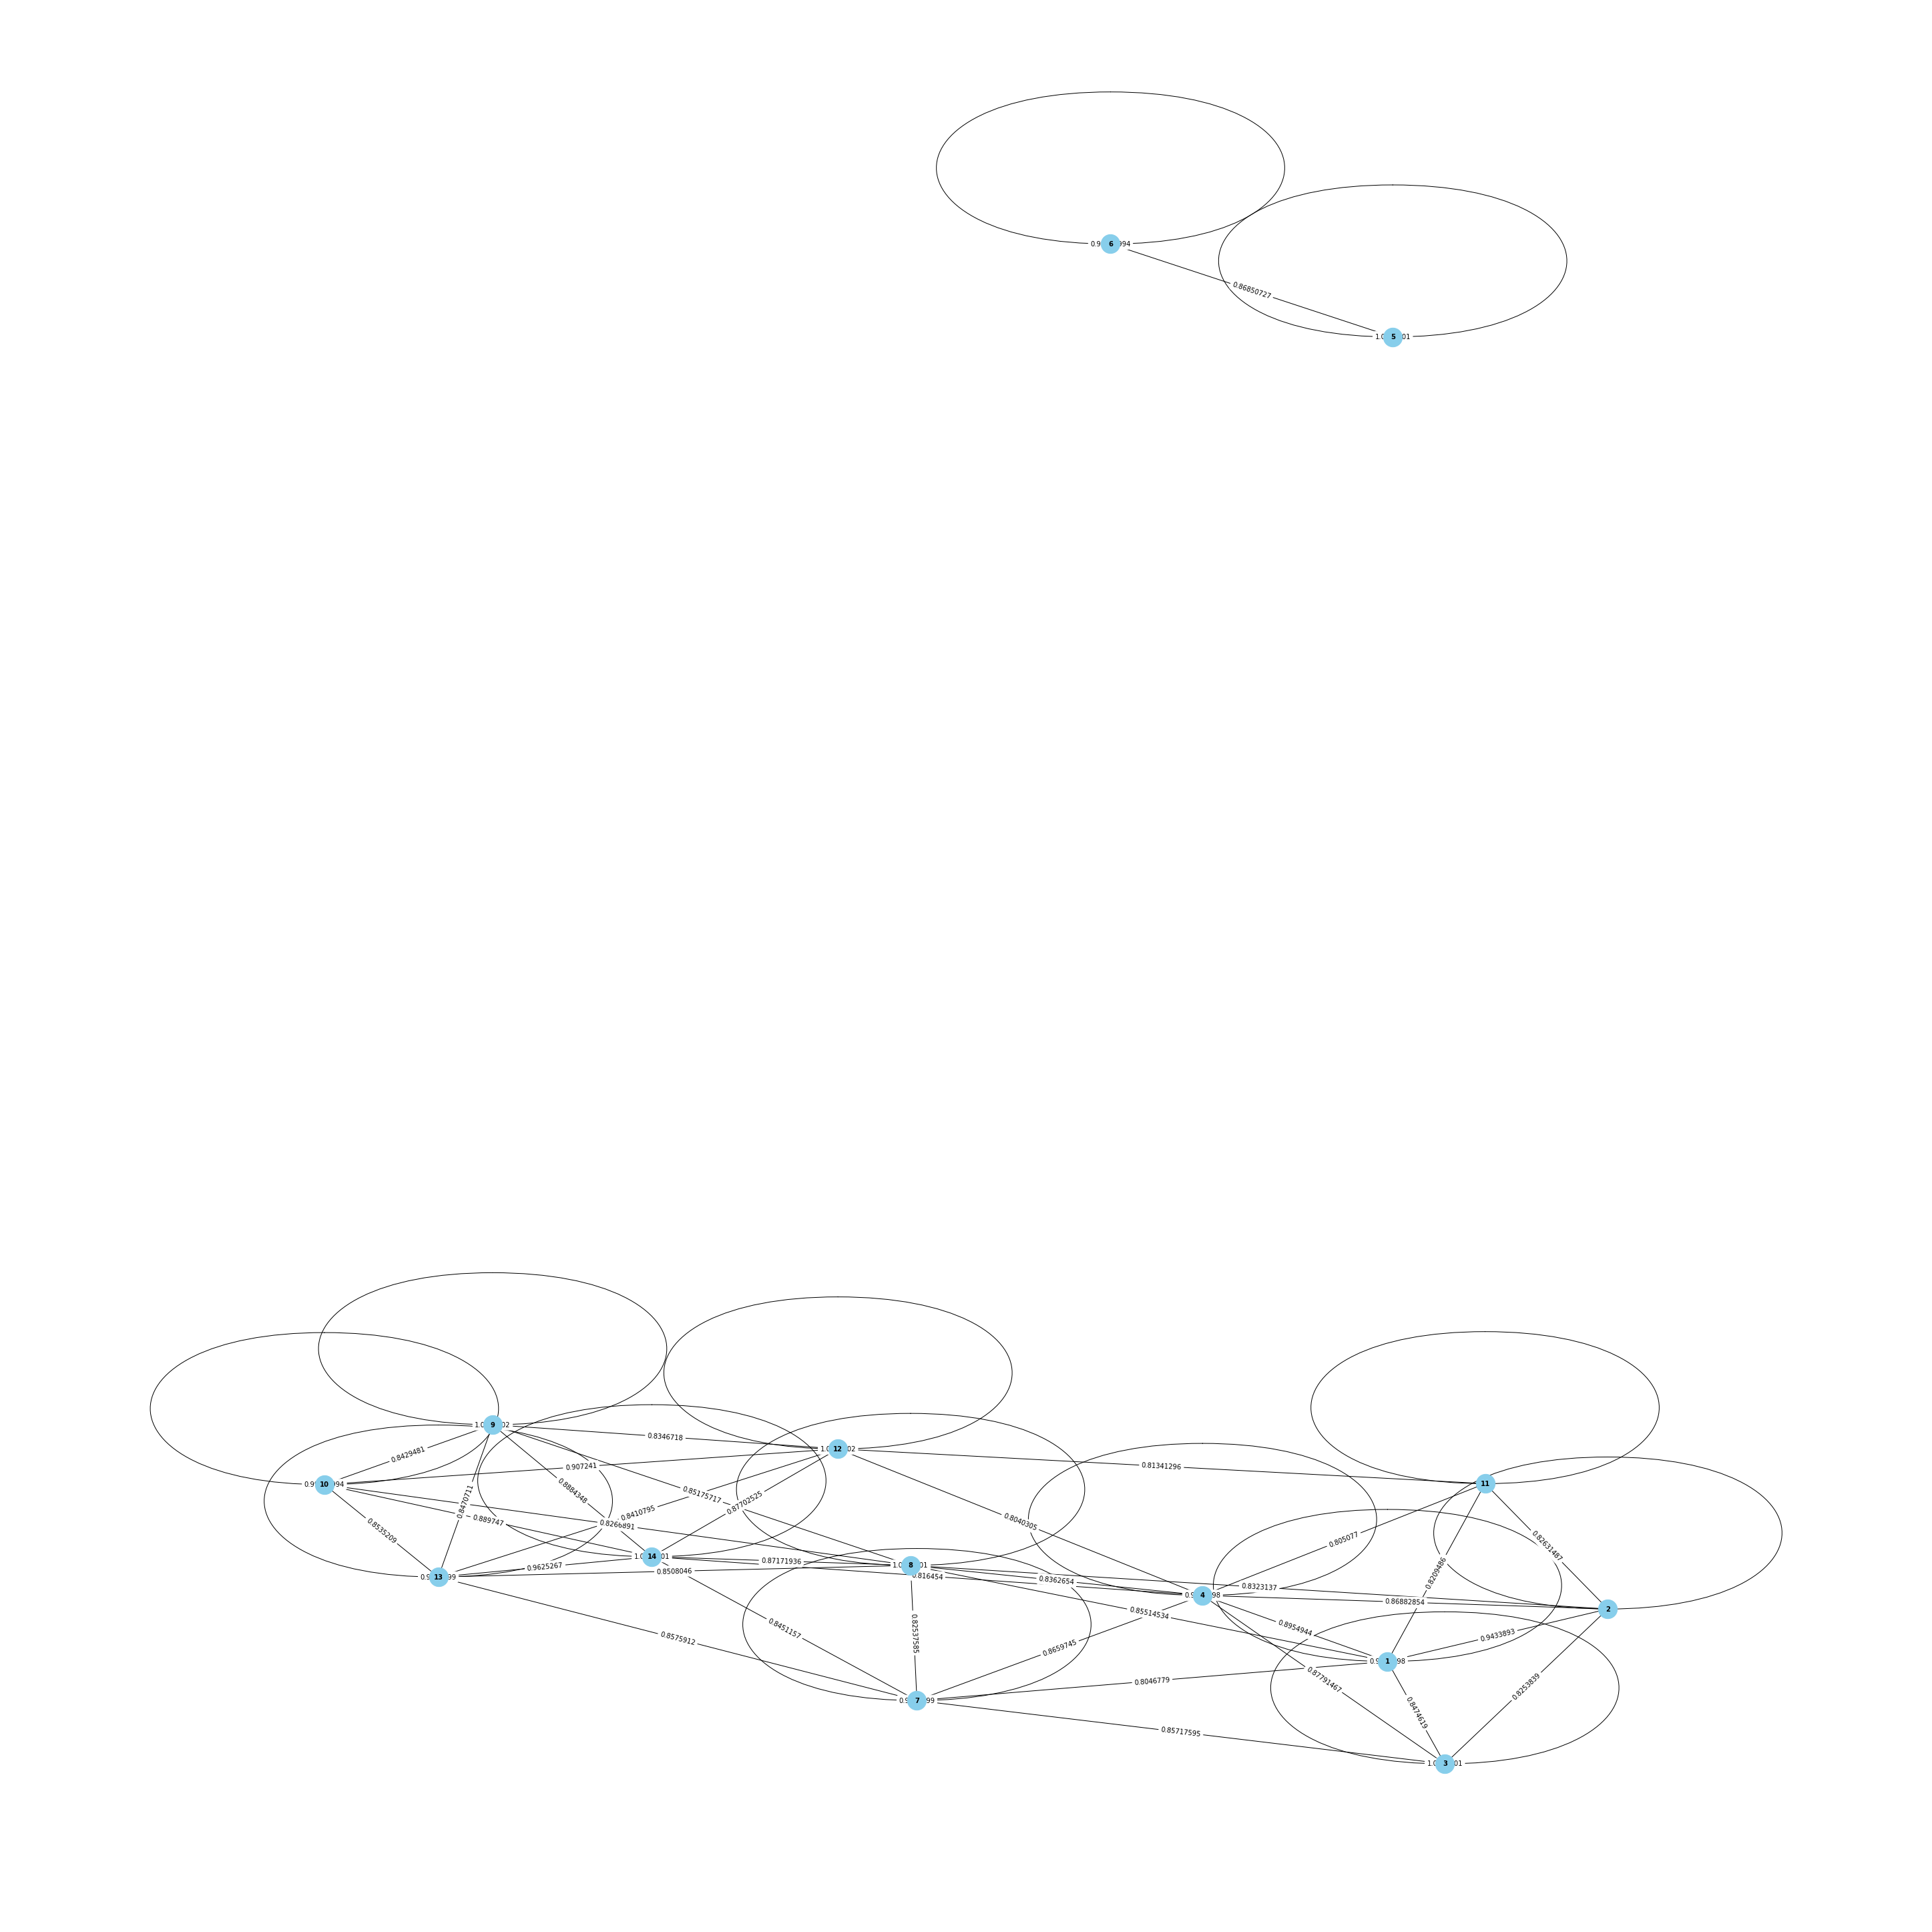

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

plt.figure(figsize=(40,40))
# Créer un graphe non dirigé
G = nx.Graph()

# Ajouter des nœuds
G.add_nodes_from([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

# Ajouter des arêtes avec des poids
for i in range(len(Tableau)):
    for j in range(len(Tableau)):
        if (i<=j) & (Tableau[i][j] > 0.8):
            G.add_edge(i+1, j+1, weight=Tableau[i][j])


# Extraire les positions des nœuds pour un dessin plus clair
pos = nx.spring_layout(G, seed=42)  # seed fixée : dessin reproductible

# Dessiner le graphe avec les poids sur les arêtes
nx.draw(G, pos, with_labels=True, font_weight='bold', node_color='skyblue', node_size=800, font_color='black', font_size=10)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

# Afficher le graphe
plt.savefig('../figures/graphe_finale.pdf')
plt.show()